In [1]:
import torch
print(torch.__version__)

print(torch.cuda.is_available())
print(torch.cuda.device_count())



2.14.1+cpu
False
0


In [2]:
import torch.nn as nn
import matplotlib.pyplot as plt

def make_generator_network(input_size = 20, num_hidden_layers =1, num_hidden_units = 100, num_output_units= 784):
  model =nn.Sequential()
  for i in range(num_hidden_layers):
    model.add_module(f"linear{i}", nn.Linear(input_size, num_hidden_units))
    model.add_module(f"acttivation_func{i}", nn.LeakyReLU())
    input_size = num_hidden_units
  model.add_module("output_layer", nn.Linear(input_size, num_output_units))

  model.add_module("tanh", nn.Tanh())

  return model





In [3]:
def make_discriminator_network(input_size = 784, num_hidden_layers = 1, num_hidden_units = 100, num_output_units =1):
  model = nn.Sequential()
  for i in range(num_hidden_layers):
    model.add_module(f"linear{i}", nn.Linear(input_size, num_hidden_units))
    model.add_module(f"acttivation_func{i}", nn.LeakyReLU())
    model.add_module("dropout", nn.Dropout(p=0.5))
    input_size = num_hidden_units
  model.add_module("output_layer", nn.Linear(input_size, num_output_units))
  model.add_module('sigmoid', nn.Sigmoid())
  return model

In [4]:
import numpy as np
image_size = (28,28)
z_size = 20
gen_hidden_layer = 1
gen_hidden_size = 100
discr_hidden_layer =1
discr_hidden_size = 100

torch.manual_seed(2)

gen_model = make_generator_network(input_size = z_size,num_hidden_layers = gen_hidden_layer,num_hidden_units= gen_hidden_size, num_output_units= np.prod(image_size))
discr_model = make_discriminator_network(input_size = np.prod(image_size), num_hidden_units = discr_hidden_size, num_hidden_layers= discr_hidden_layer)

print(gen_model)
print(discr_model)


Sequential(
  (linear0): Linear(in_features=20, out_features=100, bias=True)
  (acttivation_func0): LeakyReLU(negative_slope=0.01)
  (output_layer): Linear(in_features=100, out_features=784, bias=True)
  (tanh): Tanh()
)
Sequential(
  (linear0): Linear(in_features=784, out_features=100, bias=True)
  (acttivation_func0): LeakyReLU(negative_slope=0.01)
  (dropout): Dropout(p=0.5, inplace=False)
  (output_layer): Linear(in_features=100, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)


# Defining the training dataset
    


In [5]:
import torchvision
from torchvision import transforms

image_path ="/"
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize(mean = (0.5), std = (0.5)),
     ]
)
mnist_dataset = torchvision.datasets.MNIST(
    root = image_path,
    train = True,
    download = True,
    transform = transform
)
example, label = next(iter(mnist_dataset))

print(f'Min: {example.min()} Max: {example.max()}')
print(example.shape)

100%|██████████| 9.91M/9.91M [00:00<00:00, 14.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 395kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.68MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.03MB/s]

Min: -1.0 Max: 1.0
torch.Size([1, 28, 28])


In [6]:
# noise generation
def create_noise(batch_size, z_size, mode_x):
  if mode_x == 'normal':
    input_z = torch.randn(batch_size, z_size)*2 -1
  elif mode_x == 'uniform':
    input_z = torch.rand(batch_size, z_size)
  return input_z
  #return torch.randn(batch_size, z_size)

In [7]:
from torch.utils.data import DataLoader
batch_size = 32
dataloader = DataLoader(mnist_dataset, batch_size =32, shuffle = True)
input_real, label = next(iter(dataloader))
input_real = input_real.view(batch_size, -1)

torch.manual_seed(1)
mode_z = 'uniform'

input_z = create_noise(batch_size, z_size, mode_z)
#x_size dfn ealier
#print(input_z.shape)

In [8]:


g_output = gen_model(input_z) # outputs generated fake images
d_proba_real = discr_model(input_real) # processes real images
d_proba_fake = discr_model(g_output) # processes fake images

print('input-z -- shape:', input_z.shape)
print('input-real -- shape:', input_real.shape)
print('Output of G -- shape:', g_output.shape)
print('Disc. (real) -- shape:', d_proba_real.shape)
print('Disc. (fake) -- shape:', d_proba_fake.shape)

input-z -- shape: torch.Size([32, 20])
input-real -- shape: torch.Size([32, 784])
Output of G -- shape: torch.Size([32, 784])
Disc. (real) -- shape: torch.Size([32, 1])
Disc. (fake) -- shape: torch.Size([32, 1])


# TRAINING THE GAN MODEL


In [12]:
loss_fn = nn.BCELoss()

g_label_real = torch.ones_like(d_proba_fake)

g_loss = loss_fn(d_proba_fake, g_label_real)
print(g_loss)

# calculating Discriminator losses

d_labels_real = torch.ones_like(d_proba_real)
d_labels_fake = torch.zeros_like(d_proba_fake)

d_loss_real = loss_fn(d_proba_real, d_labels_real)
d_loss_fake = loss_fn(d_proba_fake, d_labels_fake)

print(f'Discriminator Losses: Real {d_loss_real:.4f} Fake {d_loss_fake:.4f}')

#  setting up training components

batch_size = 32
z_size = 20
gen_hidden_layer = 1
gen_hidden_size = 100
discr_hidden_layer =1
discr_hidden_size = 100
torch.manual_seed(2)
np.random.seed(2)

mnist_dl = DataLoader(mnist_dataset, batch_size =32, shuffle = True, drop_last = True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

gen_model = gen_model.to(device)
discr_model = discr_model.to(device)
loss_fn =nn.BCELoss()

G_optimizer = torch.optim.Adam(gen_model.parameters(), lr = 0.0002)
D_optimizer = torch.optim.Adam(discr_model.parameters(), lr = 0.0002)





tensor(0.6701, grad_fn=<BinaryCrossEntropyBackward0>)
Discriminator Losses: Real 0.7192 Fake 0.7170


In [13]:
# discriminatr training function
#Reset previous gradients on $D$$D$.
#Compute loss on the Real Batch (target label is 1).
#Generate fake images from random noise using $G$$G$, then compute loss on this Fake Batch (target label is 0).
#Add both losses (d_loss = d_loss_real + d_loss_fake), backpropagate, and update $D$$D$'s weights.

def d_train(x):
  discr_model.zero_grad()
  batch_size = x.shape[0]
  x = x.view(batch_size, -1).to(device)
  d_labels_real = torch.ones(batch_size, 1, device = device)

  d_proba_real = discr_model(x)

  d_loss_real = loss_fn(d_proba_real, d_labels_real)

  #fake batch pass
  input_z = create_noise(batch_size, z_size,mode_z).to(device)
  g_output = gen_model(input_z)


  #detaching
  d_proba_fake = discr_model(g_output.detach())
  d_labels_fake = torch.zeros(batch_size, 1,device= device)
  d_loss_fake = loss_fn(d_proba_fake, d_labels_fake)

  # Calculate total loss, perform backward pass and step optimizer
  d_loss = d_loss_real + d_loss_fake
  d_loss.backward()
  d_optimizer.step()

  return d_loss.data.item(), d_proba_real.detach(), d_proba_fake.detach()



# generato training function

#Reset gradients on $G$$G$.
#Create fake images using random noise.
#Feed these fake images to $D$$D$ to get predictions.
#Calculate loss comparing predictions against target 1 (representing success in fooling $D$$D$).
#Backpropagate and update $G$$G$'s weights.

def g_train(x):
  gen_model.zero_grad()
  batch_size = x.shape[0]

#generate fake images

  input_z = create_noise(batch_size, z_size,mode_z).to(device)

  input_z = create_noise(batch_size, z_size,mode_z).to(device)
  g_output = gen_model(input_z)

  d_proba_fake = discr_model(g_output)
  g_label_real = torch.ones(batch_size, 1, device = device)
  g_loss = loss_fn(d_proba_fake, g_label_real)


  g_loss.backward()
  g_optimizer.step()

  return g_loss.data.item()


In [14]:
#generate fixed noise
fixed_x = create_noise(batch_size, z_size, mode_z).to(device)

def create_samples(g_model, input_z):
  #generat fake images
  g_output =g_model(input_z)

  # 2. Reshape flat outputs back to 2D image dimension: (32, 28, 28)

  images = torch.reshape(g_output, (batch_size, *image_size))
  return (images + 1)/2.0

epoch_samples = []
all_d_losses = []
all_g_losses = []
all_d_real = []
all_d_fake = []
num_epochs = 100



# Training Loop
We train the Discriminator using the current real batch x (this also implicitly creates and evaluates fake images).

We train the Generator using the same batch configuration.

We record the losses and predictions to observe if $D$$D$ and $G$$G$ are balancing each other out (ideally, both real and fake predictions drift towards $0.5$$0.5$).

At the end of the epoch, we generate sample images using our fixed_z and store them.

In [17]:
# Map the uppercase variables from previous cells to the lowercase ones expected by d_train, g_train, and the loop
d_optimizer = D_optimizer
g_optimizer = G_optimizer
fixed_z = fixed_x

for epoch in range(1, num_epochs+1):
  d_losses,g_losses = [],[]
  d_vals_real, d_vals_fake = [], []

  for i, (x, _) in enumerate(mnist_dl):
    d_loss, d_proba_real, d_proba_fake = d_train(x)
    d_losses.append(d_loss)

    g_losses.append(g_train(x))
    d_vals_real.append(d_proba_real.mean().item())
    d_vals_fake.append(d_proba_fake.mean().item())

  all_d_losses.append(torch.tensor(d_losses).mean())
  all_g_losses.append(torch.tensor(g_losses).mean())
  all_d_real.append(torch.tensor(d_vals_real).mean())
  all_d_fake.append(torch.tensor(d_vals_fake).mean())

  print(f'Epoch {epoch:03d} | Avg Losses >> '
        f'G/D {all_g_losses[-1]:.4f}/{all_d_losses[-1]:.4f} '
        f'[D-Real: {all_d_real[-1]:.4f} '
        f'D-Fake: {all_d_fake[-1]:.4f}]')
  epoch_samples.append(create_samples(gen_model, fixed_z).detach().cpu().numpy())

Epoch 001 | Avg Losses >> G/D 0.8406/0.8988 [D-Real: 0.7795 D-Fake: 0.4550]
Epoch 002 | Avg Losses >> G/D 1.0545/0.7852 [D-Real: 0.7885 D-Fake: 0.3782]
Epoch 003 | Avg Losses >> G/D 1.0242/0.9023 [D-Real: 0.7265 D-Fake: 0.3861]
Epoch 004 | Avg Losses >> G/D 1.2991/0.7594 [D-Real: 0.7593 D-Fake: 0.3149]
Epoch 005 | Avg Losses >> G/D 1.5234/0.6673 [D-Real: 0.7897 D-Fake: 0.2667]
Epoch 006 | Avg Losses >> G/D 1.5089/0.7104 [D-Real: 0.7691 D-Fake: 0.2681]
Epoch 007 | Avg Losses >> G/D 1.6195/0.6797 [D-Real: 0.7784 D-Fake: 0.2503]
Epoch 008 | Avg Losses >> G/D 1.7389/0.6390 [D-Real: 0.7951 D-Fake: 0.2321]
Epoch 009 | Avg Losses >> G/D 1.8691/0.6043 [D-Real: 0.8082 D-Fake: 0.2130]
Epoch 010 | Avg Losses >> G/D 1.9202/0.6170 [D-Real: 0.8024 D-Fake: 0.2097]
Epoch 011 | Avg Losses >> G/D 2.0063/0.5838 [D-Real: 0.8159 D-Fake: 0.2003]
Epoch 012 | Avg Losses >> G/D 2.0335/0.5786 [D-Real: 0.8175 D-Fake: 0.1989]
Epoch 013 | Avg Losses >> G/D 2.0903/0.5788 [D-Real: 0.8182 D-Fake: 0.1946]
Epoch 014 | 

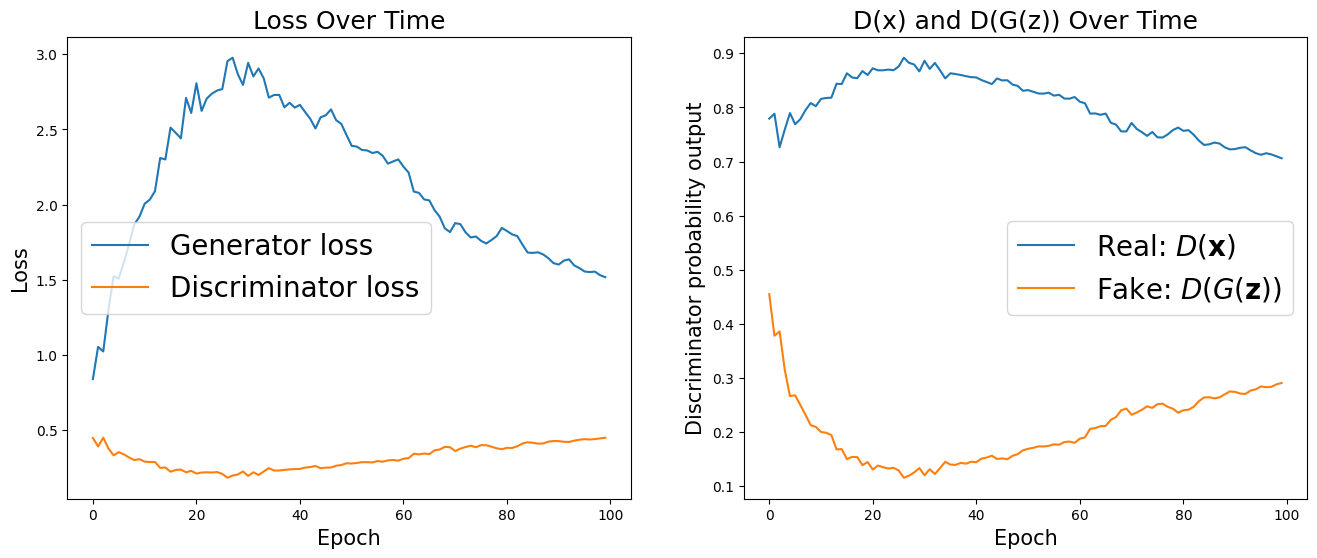

In [18]:
# Plotting Losses and Discriminator Outputs
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(16, 6))

## 1. Plotting the losses
ax = fig.add_subplot(1, 2, 1)
plt.plot(all_g_losses, label='Generator loss')
half_d_losses = [all_d_loss / 2 for all_d_loss in all_d_losses]
plt.plot(half_d_losses, label='Discriminator loss')
plt.legend(fontsize=20)
ax.set_xlabel('Epoch', size=15)
ax.set_ylabel('Loss', size=15)
ax.set_title('Loss Over Time', size=18)

## 2. Plotting the outputs of the discriminator
ax = fig.add_subplot(1, 2, 2)
plt.plot(all_d_real, label=r'Real: $D(\mathbf{x})$')
plt.plot(all_d_fake, label=r'Fake: $D(G(\mathbf{z}))$')
plt.legend(fontsize=20)
ax.set_xlabel('Epoch', size=15)
ax.set_ylabel('Discriminator probability output', size=15)
ax.set_title('D(x) and D(G(z)) Over Time', size=18)

plt.show()


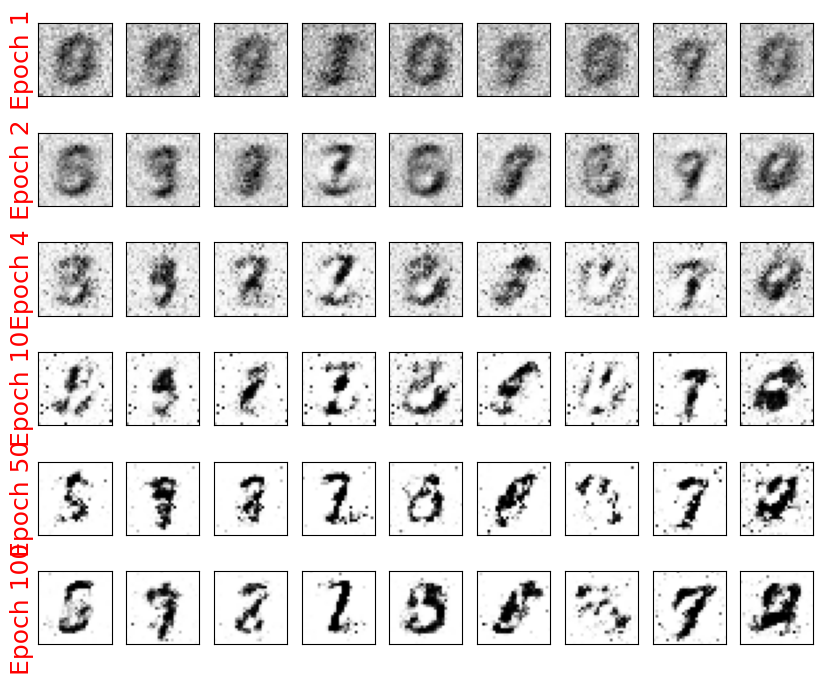

In [21]:
selected_epochs = [1, 2, 4, 10, 50, 100]
fig = plt.figure(figsize=(10, 14))

for i, e in enumerate(selected_epochs):
    for j in range(9):
        # Create subplot grid with 6 rows (milestones) and 5 columns (samples)
        ax = fig.add_subplot(10, 9, i * 9 + j + 1)
        ax.set_xticks([])
        ax.set_yticks([])

        # Print the Epoch label vertically on the far-left cell of each row
        if j == 0:
            ax.text(
                -0.06, 0.5, f'Epoch {e}',
                rotation=90, size=18, color='red',
                horizontalalignment='right',
                verticalalignment='center',
                transform=ax.transAxes
            )

        # Display the image in grayscale (inverted format for standard MNIST background)
        image = epoch_samples[e - 1][j]
        ax.imshow(image, cmap='gray_r')

plt.show()